In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

df = pd.read_csv('sales_data_sample.csv', encoding='latin-1')  
print(df.shape)
df.head()

(2823, 25)


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [ ]:
features = ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']

X = df[features].copy()
X = X.fillna(X.median())

scaler = StandardScaler()
X = scaler.fit_transform(X)

QUANTITYORDERED    0
PRICEEACH          0
SALES              0
MSRP               0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
QUANTITYORDERED,2823.0,35.092809,9.741443,6.00,27.00,35.0,43.0,97.0
PRICEEACH,2823.0,83.658544,20.174277,26.88,68.86,95.7,100.0,100.0
SALES,2823.0,3553.889072,1841.865106,482.13,2203.43,3184.8,4508.0,14082.8
MSRP,2823.0,100.715551,40.187912,33.00,68.00,99.0,124.0,214.0


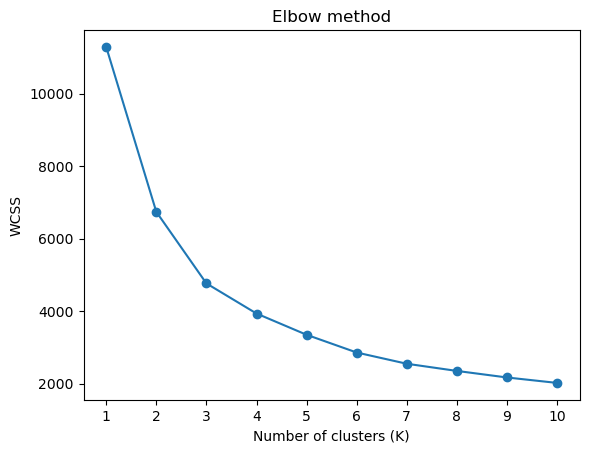

,K,WCSS
0,1,11292.0
1,2,6741.7
2,3,4766.0
3,4,3934.9
4,5,3348.3
5,6,2858.8
6,7,2548.5
7,8,2350.7
8,9,2170.0
9,10,2019.8


In [ ]:
wcss = []

for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

In [ ]:
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)

    print(k, round(silhouette_score(X, labels), 3))

K = 2  silhouette = 0.358
K = 3  silhouette = 0.351
K = 4  silhouette = 0.340
K = 5  silhouette = 0.314
K = 6  silhouette = 0.310
K = 7  silhouette = 0.312


K = 4  silhouette = 0.340
K = 5  silhouette = 0.314


K = 6  silhouette = 0.310
K = 7  silhouette = 0.312


In [ ]:
k = 3

km = KMeans(n_clusters=k, random_state=42, n_init=10)
df['KMeans_Cluster'] = km.fit_predict(X)

print(df['KMeans_Cluster'].value_counts().sort_index())

display(df.groupby('KMeans_Cluster')[features].mean().round(2))

KMeans_Cluster
0    975
1    852
2    996
Name: count, dtype: int64


,QUANTITYORDERED,PRICEEACH,SALES,MSRP
KMeans_Cluster,,,,
0,35.21,59.55,2101.08,64.15
1,43.72,97.48,5720.08,127.89
2,27.60,95.44,3123.06,113.27


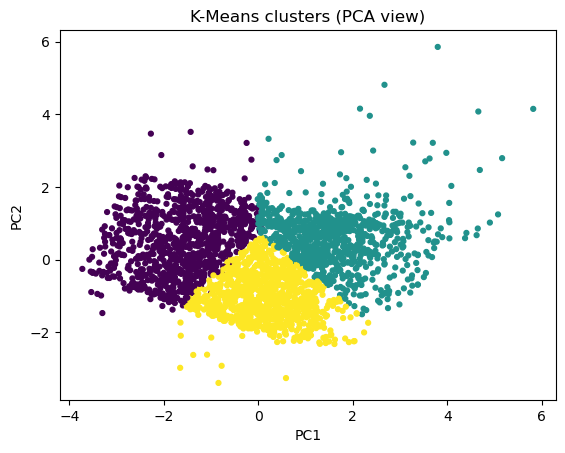

In [ ]:
pca = PCA(n_components=2)
pcs = pca.fit_transform(X)

plt.scatter(pcs[:, 0], pcs[:, 1],
            c=df['KMeans_Cluster'], cmap='viridis')

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('K-Means Clustering')
plt.show()

In [ ]:
hc = AgglomerativeClustering(n_clusters=k, linkage='ward')
df['HC_Cluster'] = hc.fit_predict(X)

print(df['HC_Cluster'].value_counts().sort_index())

display(df.groupby('HC_Cluster')[features].mean().round(2))

HC_Cluster
0    1204
1     934
2     685
Name: count, dtype: int64
Silhouette  K-Means: 0.351   Hierarchical: 0.315


,QUANTITYORDERED,PRICEEACH,SALES,MSRP
HC_Cluster,,,,
0,35.48,63.75,2273.01,70.55
1,41.71,99.29,5575.63,127.05
2,25.39,97.35,3048.60,117.84


,QUANTITYORDERED,PRICEEACH,SALES,MSRP
HC_Cluster,,,,
0,35.48,63.75,2273.01,70.55
1,41.71,99.29,5575.63,127.05
2,25.39,97.35,3048.60,117.84


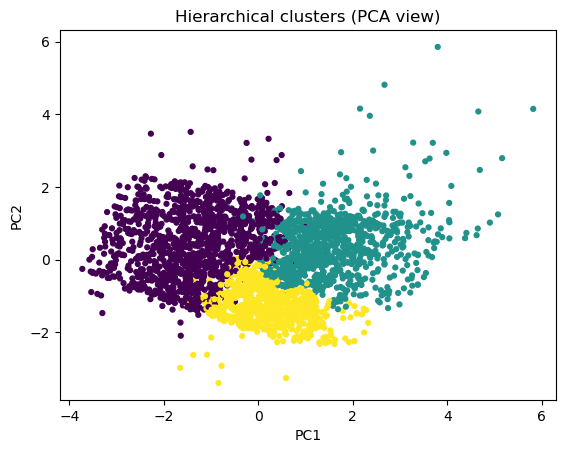

In [ ]:
plt.scatter(pcs[:, 0], pcs[:, 1],
            c=df['HC_Cluster'], cmap='viridis')

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Hierarchical Clustering')
plt.show()

In [ ]:
# linked = linkage(X, method='ward')

# plt.figure(figsize=(10, 5))
# dendrogram(linked, truncate_mode='lastp', p=20)
# plt.title('Hierarchical Clustering Dendrogram')
# plt.xlabel('Clusters')
# plt.ylabel('Distance')
# plt.show()